In [1]:
import numpy as np
from copy import deepcopy 

import matplotlib as mpl
import matplotlib.pyplot as plt
from adjustText import adjust_text

from matplotlib.patches import Circle, RegularPolygon
from matplotlib.path import Path
from matplotlib.projections import register_projection
from matplotlib.projections.polar import PolarAxes
from matplotlib.spines import Spine
from matplotlib.transforms import Affine2D

from util import *


EXT='pdf'
DPI=400

In [2]:
models = list_models()
models

         Expected models: ['gooey', 'neongooey', 'proteus', 'pacman', 'lincs', 'moai', 'planatmo']
         Found models: ['gooey', 'lincs', 'moai', 'neongooey', 'pacman', 'planatmo', 'proteus', 'lavatmos3', 'magmavol_massbalance', 'magmavol_meltfug']


['gooey', 'neongooey', 'proteus', 'pacman', 'lincs', 'moai', 'planatmo']

In [3]:
models_data = {}
for m in models:
    models_data[m] = load_model_data(m, quiet=True)

Loading model gooey
Loading model neongooey
Loading model proteus
Loading model pacman
Loading model lincs
Loading model moai
Loading model planatmo


In [4]:
planets = list_planets()
planets

('earth', 'venus')

In [5]:
print(", ".join(models_data["proteus"]["earth"]["Hhigh-Chigh-evo"].keys()))

t(yr), T_surf(K), T_pot(K), flux_surf(W/m2), flux_OLR(W/m2), flux_ASR(W/m2), phi(vol_frac), fO2_melt(bar), fO2_solid(bar), thick_surf_bl(m), massC_solid(kg), massC_melt(kg), massC_atm(kg), massH_solid(kg), massH_melt(kg), massH_atm(kg), massO_atm(kg), p_surf(bar), p_H2O(bar), p_CO2(bar), p_CO(bar), p_H2(bar), p_CH4(bar), p_O2(bar), mmw(kg/mol), R_trans(m), R_solid(m), viscosity(Pa.s), phi(mass_frac), p_SO2(bar), p_NH3(bar), p_N2(bar), p_H2S(bar), p_S2(bar)


gooey earth nominal
Partitioning:
        H partitioning at t=0.40 Myr: atm=90.2%, melt=4.8%, solid=5.0%
        O partitioning at t=0.40 Myr: atm=100.0%, melt=0.0%, solid=0.0%
    CBL thick at t=0.28 Myr, thick=1.0 m
    at melt fraction = 0.663%


/tmp/ipykernel_2170/4291553331.py:132: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = ax.legend(loc=loc, bbox_to_anchor=bbx, ncol=ncol,


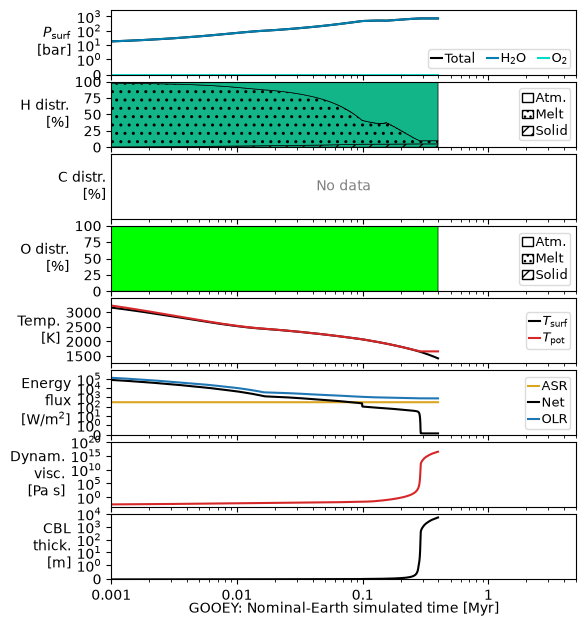

gooey venus nominal
Partitioning:
        H partitioning at t=0.45 Myr: atm=93.1%, melt=2.2%, solid=4.7%
        O partitioning at t=0.45 Myr: atm=100.0%, melt=0.0%, solid=0.0%
    CBL thick at t=0.31 Myr, thick=1.0 m
    at melt fraction = 0.845%


/tmp/ipykernel_2170/4291553331.py:151: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()


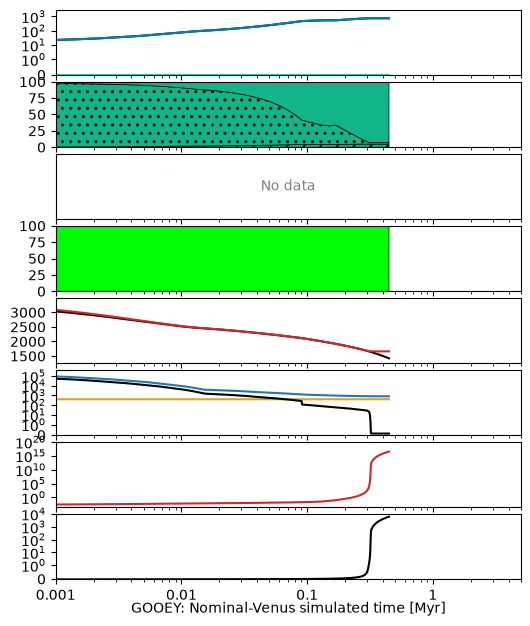

neongooey earth nominal
Partitioning:
        H partitioning at t=3.78 Myr: atm=83.8%, melt=11.6%, solid=4.7%
        C partitioning at t=3.78 Myr: atm=99.8%, melt=0.2%, solid=0.0%
        O partitioning at t=3.78 Myr: atm=100.0%, melt=0.0%, solid=0.0%
    CBL thick at t=3.78 Myr, thick=5221.8 m
    at melt fraction = 0.622%


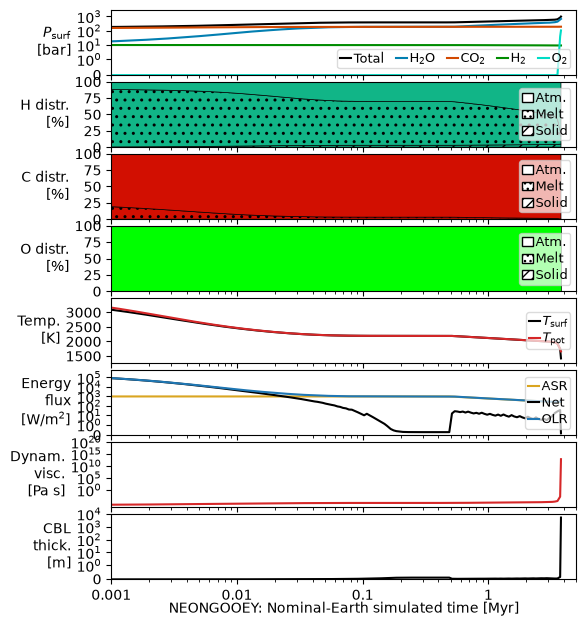

neongooey venus nominal
Partitioning:
        H partitioning at t=13.25 Myr: atm=82.0%, melt=12.8%, solid=5.2%
        C partitioning at t=13.25 Myr: atm=99.8%, melt=0.2%, solid=0.0%
        O partitioning at t=13.25 Myr: atm=100.0%, melt=0.0%, solid=0.0%
    CBL thick at t=13.25 Myr, thick=5821.1 m
    at melt fraction = 0.761%


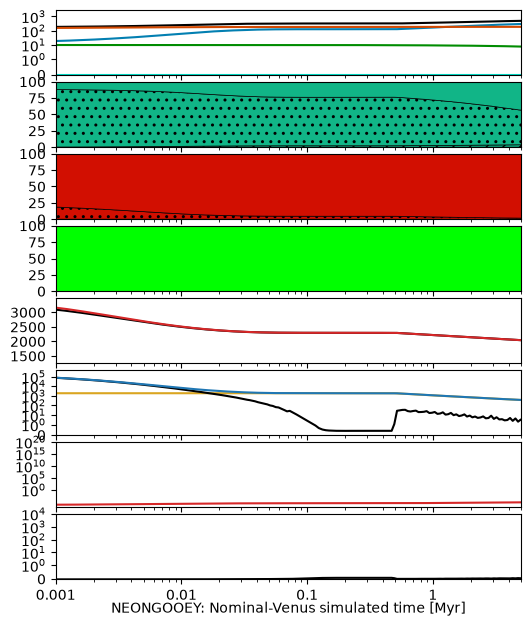

proteus earth nominal
Partitioning:
        H partitioning at t=0.47 Myr: atm=46.2%, melt=53.8%, solid=0.0%
        C partitioning at t=0.47 Myr: atm=99.1%, melt=0.9%, solid=0.0%
        O partitioning at t=0.47 Myr: atm=100.0%, melt=0.0%, solid=0.0%


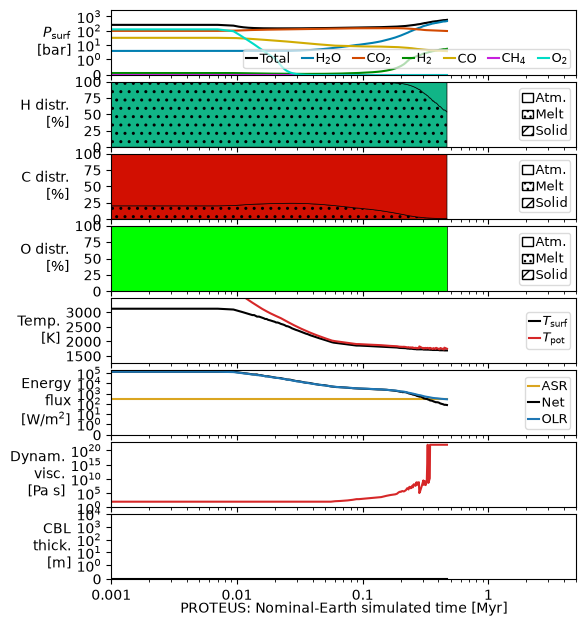

proteus venus nominal
Partitioning:
        H partitioning at t=39.33 Myr: atm=45.9%, melt=54.1%, solid=0.0%
        C partitioning at t=39.33 Myr: atm=99.3%, melt=0.7%, solid=0.0%
        O partitioning at t=39.33 Myr: atm=100.0%, melt=0.0%, solid=0.0%


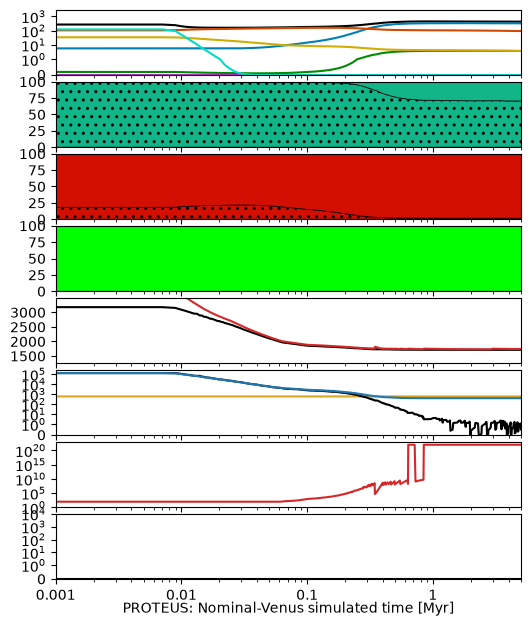

pacman earth nominal
Partitioning:
        H partitioning at t=1.15 Myr: atm=5.1%, melt=37.3%, solid=57.6%
        C partitioning at t=1.15 Myr: atm=91.4%, melt=1.8%, solid=6.8%
        O partitioning at t=1.15 Myr: atm=100.0%, melt=0.0%, solid=0.0%
    CBL thick at t=0.30 Myr, thick=1.0 m
    at melt fraction = 2.080%


/tmp/ipykernel_2170/4291553331.py:48: RuntimeWarning: invalid value encountered in divide
  part_this["solid"] = dat[f"mass{elem}_solid(kg)"].values/tot*100
/tmp/ipykernel_2170/4291553331.py:56: RuntimeWarning: invalid value encountered in divide
  part_this["melt"] = dat[f"mass{elem}_melt(kg)"].values/tot*100
/tmp/ipykernel_2170/4291553331.py:64: RuntimeWarning: invalid value encountered in divide
  part_this["atm"] = dat[f"mass{elem}_atm(kg)"].values/tot*100


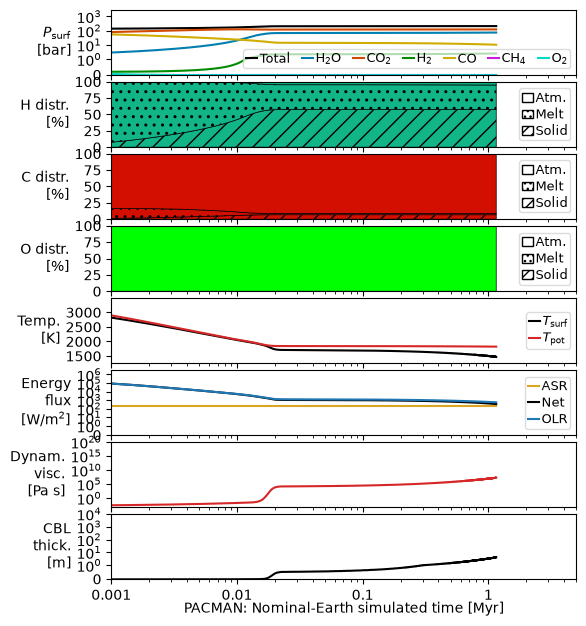

pacman venus nominal
Partitioning:
        H partitioning at t=2.20 Myr: atm=5.8%, melt=39.6%, solid=54.6%
        C partitioning at t=2.20 Myr: atm=92.1%, melt=1.8%, solid=6.1%
        O partitioning at t=2.20 Myr: atm=100.0%, melt=0.0%, solid=0.0%
    CBL thick at t=0.39 Myr, thick=1.0 m
    at melt fraction = 2.433%


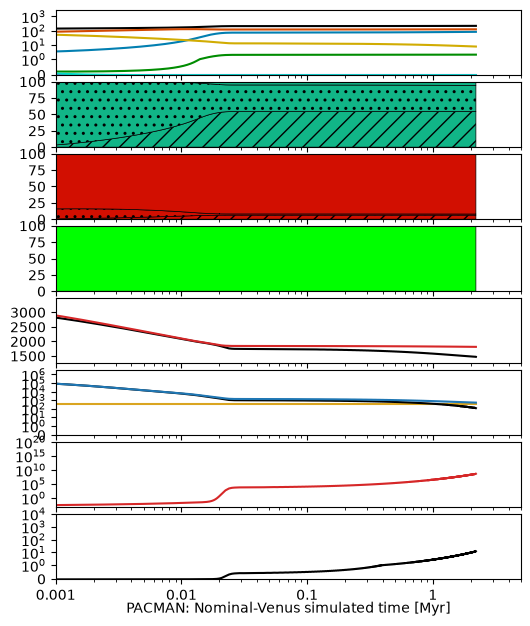

lincs earth nominal
Partitioning:
        H partitioning at t=0.38 Myr: atm=96.6%, melt=0.0%, solid=3.4%
        C partitioning at t=0.38 Myr: atm=nan%, melt=nan%, solid=nan%
        O partitioning at t=0.38 Myr: atm=100.0%, melt=0.0%, solid=0.0%


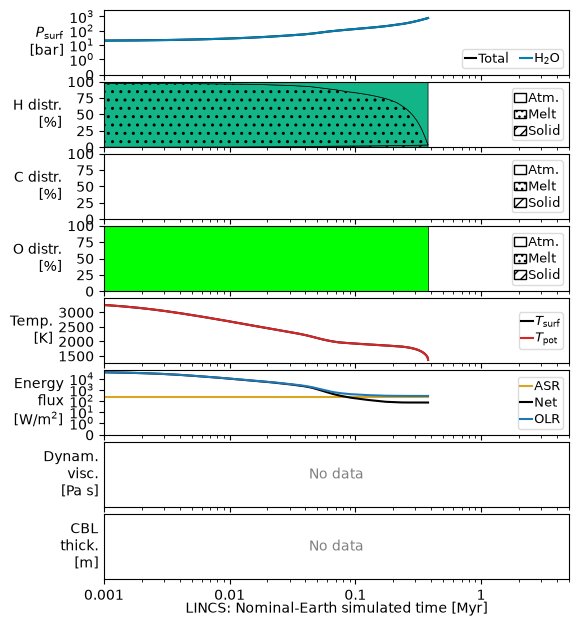

lincs venus nominal
Partitioning:
        H partitioning at t=49.28 Myr: atm=46.1%, melt=0.0%, solid=53.9%
        C partitioning at t=49.28 Myr: atm=nan%, melt=nan%, solid=nan%
        O partitioning at t=49.28 Myr: atm=100.0%, melt=0.0%, solid=0.0%


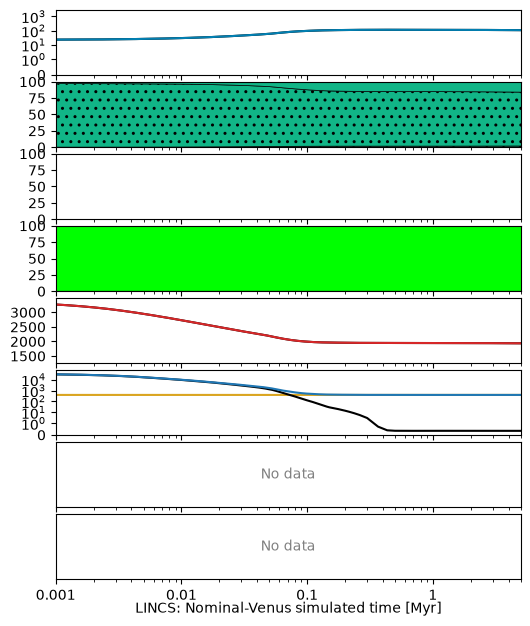

moai earth nominal
Partitioning:
        H partitioning at t=0.24 Myr: atm=8.2%, melt=2.5%, solid=89.3%
        C partitioning at t=0.24 Myr: atm=93.9%, melt=0.1%, solid=6.0%


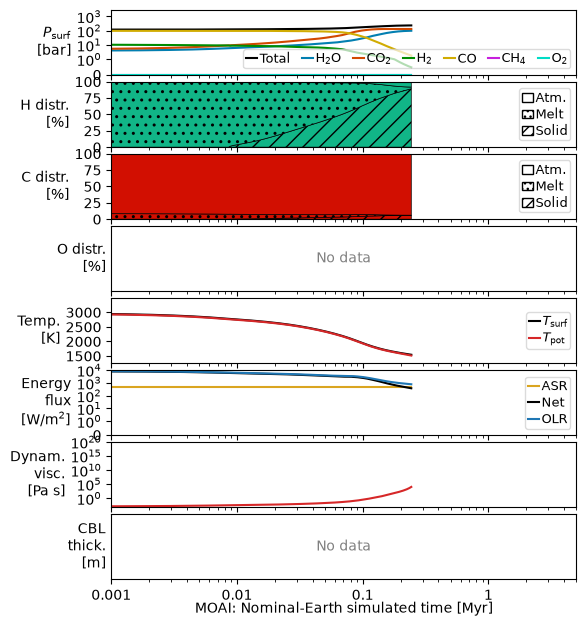

moai venus nominal
Partitioning:
        H partitioning at t=0.45 Myr: atm=7.1%, melt=2.3%, solid=90.6%
        C partitioning at t=0.45 Myr: atm=94.4%, melt=0.1%, solid=5.5%


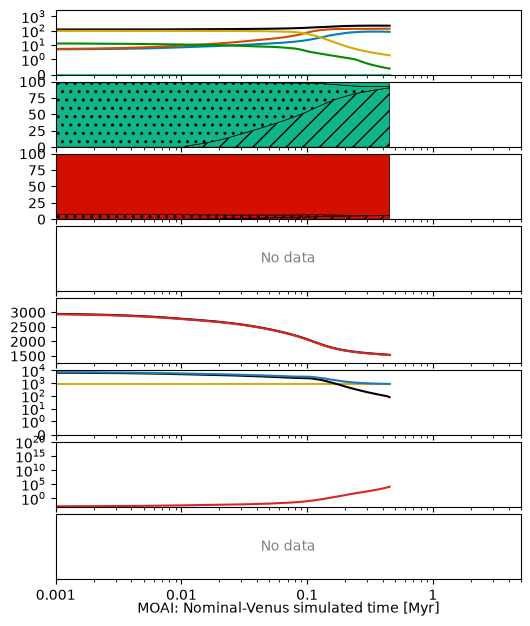

planatmo earth nominal
Partitioning:
        H partitioning at t=0.16 Myr: atm=92.6%, melt=0.4%, solid=6.9%
        C partitioning at t=0.16 Myr: atm=100.0%, melt=0.0%, solid=0.0%
        O partitioning at t=0.16 Myr: atm=100.0%, melt=0.0%, solid=0.0%


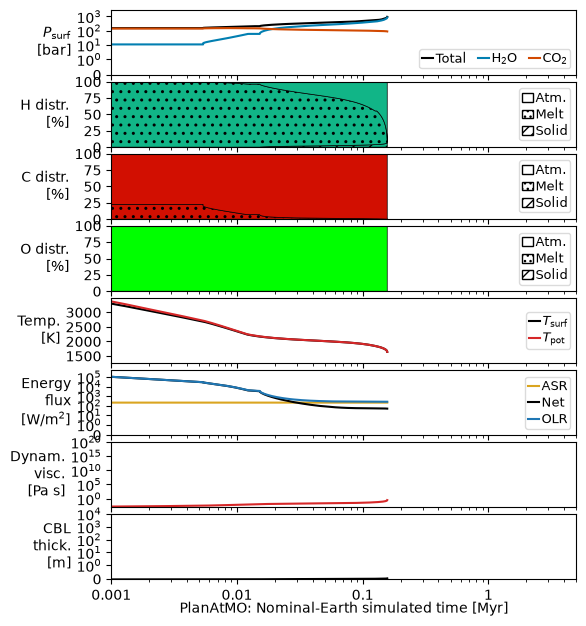

planatmo venus nominal
Partitioning:
        H partitioning at t=0.08 Myr: atm=10.6%, melt=88.4%, solid=1.0%
        C partitioning at t=0.08 Myr: atm=97.0%, melt=3.0%, solid=0.0%
        O partitioning at t=0.08 Myr: atm=100.0%, melt=0.0%, solid=0.0%


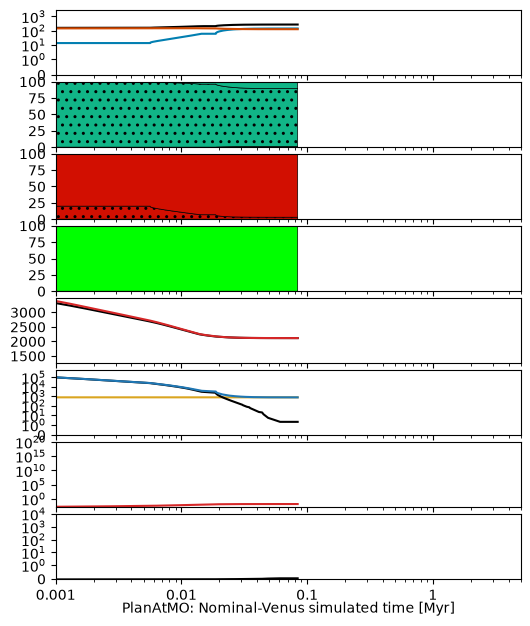

In [68]:
def plot_overview(model, planet, case, ylabels=False, legends=False):

    print(model, planet, case)

    Nax = 8
    fig,axs = plt.subplots(Nax,1, figsize=(6,0.6+0.85*Nax), sharex=True)

    dat = deepcopy(models_data[model][planet][case+"-evo"])
    x = dat["t(yr)"]/1e6

    # Surface pressure
    ax = axs[0]
    ax.plot(x, dat["p_surf(bar)"], label="Total", color="k")
    for gas in chili_gases:
        y = dat[f"p_{gas}(bar)"]
        if np.any(y > 0):
            ax.plot(x, y, label=get_label(gas), color=get_color(gas))
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylabel(r"$P_{\rm surf}$"+"\n[bar]", rotation=0, ha='right', va='center')
    ax.set_ylim(bottom=0, top=3e3)

    # Partitioning (stacked fill-between, one panel per element)
    partition = {}
    print("Partitioning:")
    for iax, elem in enumerate(["H", "C", "O"]):
        ax = axs[1+iax]
        col = get_color(elem)

        ax.set_ylabel(f"{elem} distr.\n[%]", rotation=0, ha='right', va='center')
        ax.set_ylim(bottom=0, top=100)
        ax.set_yticks([0, 25, 50, 75, 100])

        part_this = {'tot': [0.0], 'atm': [0.0], 'melt': [0.0], 'solid': [0.0]}

        # get total
        tot = np.zeros_like(x)
        for res in ["atm", "melt", "solid"]:
            key = f"mass{elem}_{res}(kg)"
            if key not in dat:
                dat[key] = np.zeros_like(x)
            tot += dat[key].values
        if tot is None or np.all(tot == 0):
            partition[elem] = part_this
            continue
        part_this["tot"] = tot

        # solid phase
        part_this["solid"] = dat[f"mass{elem}_solid(kg)"].values/tot*100
        y0 = np.zeros_like(x)
        y1 = part_this["solid"]
        ax.fill_between(x, y0, y1,
                        color=col, edgecolor='k', lw=0.5,
                        hatch='//', hatchcolor='k', )

        # melt phase
        part_this["melt"] = dat[f"mass{elem}_melt(kg)"].values/tot*100
        y0 = y1
        y1 = y0 + part_this["melt"]
        ax.fill_between(x, y0, y1, 
                        color=col, edgecolor='k', lw=0.5,
                        hatch='..', hatchcolor='k', )

        # atm phase
        part_this["atm"] = dat[f"mass{elem}_atm(kg)"].values/tot*100
        y0 = y1
        y1 = y0 + part_this["atm"]
        ax.fill_between(x, y0, y1,
                        color=col, edgecolor='k', lw=0.5,
                        hatch='', hatchcolor='k', )
        

        ax.fill([],[], color='w', hatch='',    hatchcolor='k', ec='k', label="Atm.")
        ax.fill([],[], color='w', hatch='...', hatchcolor='k', ec='k', label="Melt")
        ax.fill([],[], color='w', hatch='///', hatchcolor='k', ec='k', label="Solid")
        partition[elem] = part_this
        print(f"        {elem} partitioning at t={x.values[-1]:.2f} Myr: atm={part_this['atm'][-1]:.1f}%, melt={part_this['melt'][-1]:.1f}%, solid={part_this['solid'][-1]:.1f}%")

    # Temperatures
    ax = axs[4]
    ax.plot(x, dat["T_surf(K)"], c='black',   label=r"$T_{\rm surf}$")
    ax.plot(x, dat["T_pot(K)"],  c='tab:red', label=r"$T_{\rm pot}$")
    ax.set_ylabel("Temp.\n[K]", rotation=0, ha='right', va='center')
    ax.set_ylim(bottom=1250, top=3500)
    ax.set_yticks([1500, 2000, 2500, 3000])

    # Fluxes
    ax = axs[5]
    ax.plot(x, dat["flux_ASR(W/m2)"],   c='goldenrod', label="ASR")
    ax.plot(x, dat["flux_surf(W/m2)"],  c='black',    label="Net")
    ax.plot(x, dat["flux_OLR(W/m2)"],   c='tab:blue', label="OLR")
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylabel("Energy\nflux\n[W/m$^2$]", rotation=0, ha='right', va='center')
    ax.set_ylim(bottom=0)

    # Viscosity
    ax = axs[6]
    y = dat["viscosity(Pa.s)"]
    ax.set_ylabel("Dynam.\nvisc.\n[Pa s]", rotation=0, ha='right', va='center')
    if np.any(y > 0):
        ax.plot(x, y, c='tab:red', label="viscosity")
        ax.set_yscale("log")
        ax.set_yticks([1, 1e5, 1e10, 1e15, 1e20])

    # Skin thickness
    ax = axs[7]
    y = dat.get("thick_surf_bl(m)", np.zeros_like(x))
    ax.set_ylabel("CBL\nthick.\n[m]", rotation=0, ha='right', va='center')
    if np.any(y > 0):
        
        ax.plot(x, y, c='k', label="CBL [m]")
        ax.set_yscale("symlog", linthresh=1)
        ax.set_ylim(bottom=0, top=1e4)

        # print when CBL thickness increases
        for xi, yi in zip(x, y):
            if yi > 1:
                print(f"    CBL thick at t={xi:.2f} Myr, thick={yi:.1f} m")
                print(f"    at melt fraction = {100*dat['phi(vol_frac)'][np.argmin(np.abs(x-xi))]:.3f}%")
                break

    
    for iax,ax in enumerate(axs):
        ncol = 1
        loc = 'center right'
        bbx = (1.0, 0.5)

        if iax == 0:
            loc = 'lower right'
            bbx = (1.0, 0.01)
            ncol = 8

        leg = ax.legend(loc=loc, bbox_to_anchor=bbx, ncol=ncol,
                        framealpha=0.7,
                        fontsize=9, handletextpad=0.2, columnspacing=0.9, 
                        handlelength=0.9, labelspacing=0.2, borderpad=0.2,
                        frameon=True)
        
        # if legend is empty
        leg_len = len(leg.get_texts())
        if leg_len == 0:
            leg.remove()
            ax.text(0.5, 0.5, "No data", ha='center', va='center', transform=ax.transAxes, fontsize=10, color='gray')
            ax.set_yticks([])
        elif leg_len == 1:
            leg.remove()

        # remove ylabels for all but earth
        if not ylabels:
            ax.set_ylabel("")
        if not legends:
            ax.legend().remove()

    lbl = case
    if lbl == "nominal":
        lbl = "Nominal"
    title = get_label(model) + ": " + lbl + "-"+ get_label(planet)  + " simulated time [Myr]"
    axs[-1].set_xlabel(title , labelpad=-1)
    axs[-1].set_xscale("log")
    axs[-1].set_xlim(left=1e-3, right=5)
    axs[-1].xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))

    fig.subplots_adjust(hspace=0.1)

    plt.show()
    fig.savefig(f"out/overview_{model}_{planet}_{case}.{EXT}", bbox_inches='tight', dpi=DPI, pad_inches=0.03)


for model in models:
    for planet in planets:
        ylabels = bool(planet == "earth" )
        plot_overview(model, planet, "nominal", ylabels=ylabels, legends=ylabels)